# Auditoria de Calçadas — Treinamento, validação e exportação do YOLOv8n

**CPZÃO (CP2 + CP3) · Visão Computacional**

Este notebook faz a parte 2 do pipeline:

1. Lê o dataset rotulado (`data/labels`, gerado a partir da pré-anotação + revisão manual, ver scripts `01`–`04`).
2. Divide em **treino / validação / teste** (70 / 20 / 10, semente fixa).
3. Treina um **YOLOv8n** (pré-treinado no COCO) com *fine-tuning* nas 4 classes.
4. Analisa as métricas: curvas de perda, **mAP@50**, **mAP@50-95**, **Precision**, **Recall**, **matriz de confusão**.
5. Avalia no conjunto de **teste** (nunca visto no treino nem na escolha de hiperparâmetros).
6. **Exporta para ONNX** (formato usado pelo `yoloinferApp`, que roda com ONNX Runtime Web no celular) e valida a exportação.

Classes: `0 buraco` · `1 lixo` · `2 piso_tatil` · `3 poste`

In [1]:
import os, glob, random, shutil, json, yaml
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, ultralytics
from ultralytics import YOLO

RAIZ = Path('..').resolve()          # raiz do repositório
IMGS = RAIZ / 'data/raw/imagens'
LABELS = RAIZ / 'data/labels'
DATASET = RAIZ / 'data/dataset'      # estrutura YOLO gerada aqui
NOMES = ['buraco', 'lixo', 'piso_tatil', 'poste']
SEED = 42
IMGSZ = 448                          # fotos têm 440x248 -> 448 preserva a resolução original
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__,
      '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

ultralytics 8.4.176 | torch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 5060 Ti


## 1. Dataset: estatísticas

In [2]:
rotuladas = sorted(p.stem for p in LABELS.glob('*.txt'))
linhas = []
for n in rotuladas:
    for l in (LABELS / f'{n}.txt').read_text().split('\n'):
        if l.strip():
            c, cx, cy, w, h = l.split()
            linhas.append(dict(img=n, classe=NOMES[int(c)], w=float(w) * 440, h=float(h) * 248))
df = pd.DataFrame(linhas)
negativas = len(rotuladas) - df.img.nunique()
print(f'Imagens rotuladas: {len(rotuladas)}  (com objetos: {df.img.nunique()}, negativas/sem objeto: {negativas})')
print(f'Total de caixas: {len(df)}')
resumo = df.groupby('classe').agg(caixas=('img', 'size'), imagens=('img', 'nunique'),
                                  largura_media_px=('w', 'mean'), altura_media_px=('h', 'mean')).round(1)
resumo

Imagens rotuladas: 167  (com objetos: 135, negativas/sem objeto: 32)
Total de caixas: 298


,caixas,imagens,largura_media_px,altura_media_px
classe,,,,
buraco,20,20,91.8,41.6
lixo,65,45,47.0,36.3
piso_tatil,26,24,104.8,149.7
poste,187,111,20.5,84.8


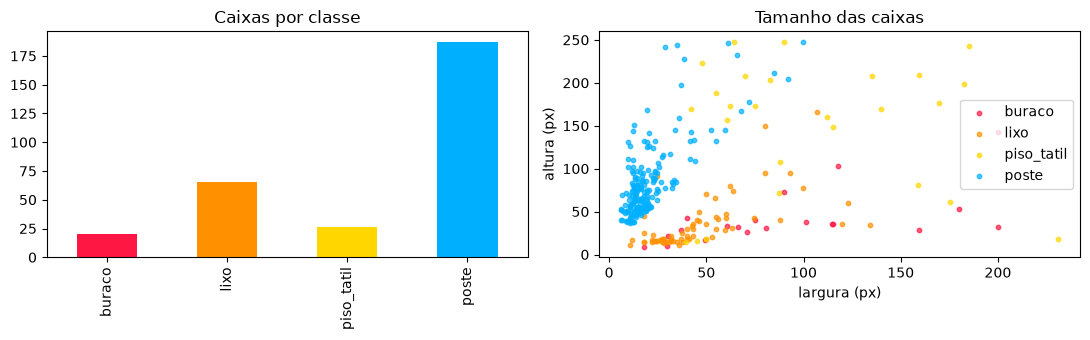

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
resumo['caixas'].plot.bar(ax=ax[0], color=['#ff1744', '#ff9100', '#ffd600', '#00b0ff'])
ax[0].set_title('Caixas por classe'); ax[0].set_xlabel('')
for c, cor in zip(NOMES, ['#ff1744', '#ff9100', '#ffd600', '#00b0ff']):
    d = df[df.classe == c]
    ax[1].scatter(d.w, d.h, s=10, label=c, color=cor, alpha=.7)
ax[1].set_xlabel('largura (px)'); ax[1].set_ylabel('altura (px)'); ax[1].set_title('Tamanho das caixas'); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Divisão treino / validação / teste

Divisão aleatória com semente fixa (70/20/10), garantindo que **cada classe apareça nos três conjuntos**
(a semente é sorteada de novo até isso acontecer — com dataset pequeno isso evita um teste sem nenhum `buraco`, por exemplo).

In [4]:
def divide(nomes, seed):
    r = random.Random(seed); nomes = nomes[:]; r.shuffle(nomes)
    n = len(nomes); a, b = int(.7 * n), int(.9 * n)
    return {'train': nomes[:a], 'val': nomes[a:b], 'test': nomes[b:]}

def classes_de(lista):
    return set(df[df.img.isin(lista)].classe)

seed = SEED
while True:
    split = divide(rotuladas, seed)
    if all(classes_de(split[s]) == set(NOMES) for s in split):
        break
    seed += 1
print('semente usada:', seed)

if DATASET.exists():
    shutil.rmtree(DATASET)
for s, nomes in split.items():
    (DATASET / s / 'images').mkdir(parents=True); (DATASET / s / 'labels').mkdir(parents=True)
    for n in nomes:
        shutil.copy(IMGS / f'{n}.jpg', DATASET / s / 'images')
        shutil.copy(LABELS / f'{n}.txt', DATASET / s / 'labels')

data_yaml = DATASET / 'data.yaml'
data_yaml.write_text(yaml.safe_dump({'path': str(DATASET), 'train': 'train/images', 'val': 'val/images',
                                     'test': 'test/images', 'names': dict(enumerate(NOMES))}, allow_unicode=True))
(RAIZ / 'data/split.json').write_text(json.dumps(split, indent=1))

tab = pd.DataFrame({s: Counter(df[df.img.isin(n)].classe) for s, n in split.items()}).fillna(0).astype(int)
tab.loc['imagens'] = [len(split[s]) for s in tab.columns]
tab

semente usada: 42


,train,val,test
poste,131,32,24
piso_tatil,17,5,4
lixo,45,13,7
buraco,15,4,1
imagens,116,34,17


## 3. Treinamento

* Modelo: **YOLOv8n** pré-treinado no COCO (3,2 M parâmetros — leve o suficiente para rodar no navegador do celular).
* `imgsz=448`: as fotos da auditoria têm 440×248, então 448 mantém a resolução original (sem upscaling inútil).
* Aumentação de dados padrão da Ultralytics (mosaic, HSV, flip horizontal, escala, translação) — importante com poucas imagens.
* `patience=40`: *early stopping* se o mAP de validação parar de melhorar.

In [5]:
model = YOLO('yolov8n.pt')
res = model.train(data=str(data_yaml), imgsz=IMGSZ, epochs=150, patience=40, batch=16, seed=SEED,
                  project=str(RAIZ / 'runs'), name='calcadas', exist_ok=True, plots=True, verbose=False,
                  workers=0)
RUN = Path(res.save_dir)
print('pesos:', RUN / 'weights/best.pt')

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\rafae\AppData\Local\Temp\cp\repo\data\dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=448, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=calcadas, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=40, persp

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3it/s 0.6s

                   all         34         54      0.376      0.322      0.293      0.179


Speed: 0.1ms preprocess, 2.1ms inference, 0.0ms loss, 3.8ms postprocess per image


Results saved to C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas


pesos: C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.pt


## 4. Curvas de treino (perdas e métricas por época)

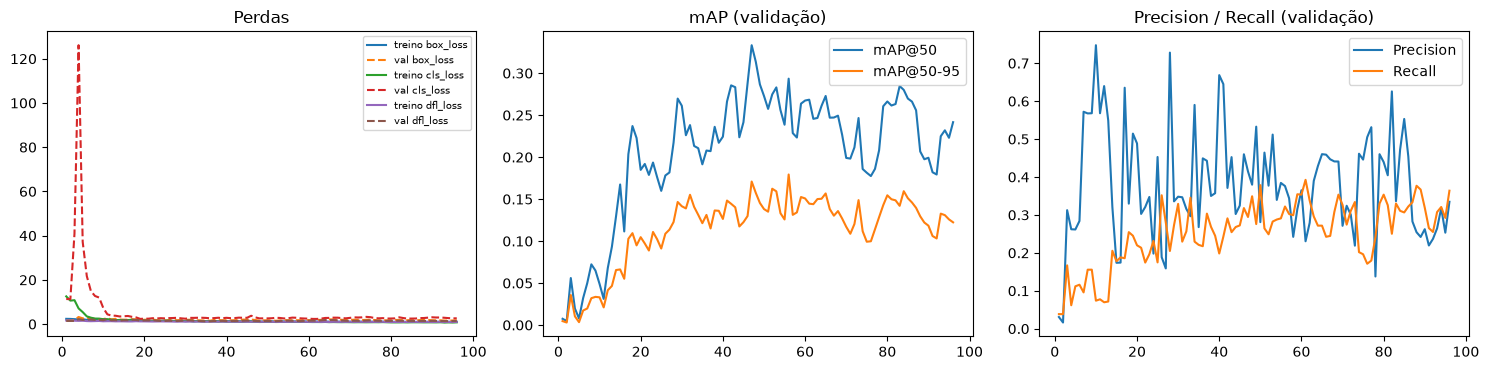

melhor época: 47 | mAP@50=0.333 | mAP@50-95=0.171


In [6]:
r = pd.read_csv(RUN / 'results.csv'); r.columns = r.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k in ['box_loss', 'cls_loss', 'dfl_loss']:
    ax[0].plot(r.epoch, r[f'train/{k}'], label=f'treino {k}')
    ax[0].plot(r.epoch, r[f'val/{k}'], '--', label=f'val {k}')
ax[0].set_title('Perdas'); ax[0].legend(fontsize=7)
ax[1].plot(r.epoch, r['metrics/mAP50(B)'], label='mAP@50'); ax[1].plot(r.epoch, r['metrics/mAP50-95(B)'], label='mAP@50-95')
ax[1].set_title('mAP (validação)'); ax[1].legend()
ax[2].plot(r.epoch, r['metrics/precision(B)'], label='Precision'); ax[2].plot(r.epoch, r['metrics/recall(B)'], label='Recall')
ax[2].set_title('Precision / Recall (validação)'); ax[2].legend()
plt.tight_layout(); plt.show()
melhor = r.loc[r['metrics/mAP50(B)'].idxmax()]
print(f"melhor época: {int(melhor.epoch)} | mAP@50={melhor['metrics/mAP50(B)']:.3f} | mAP@50-95={melhor['metrics/mAP50-95(B)']:.3f}")

### Por que YOLOv8n com 448 px? (comparação de configurações)

O script [`scripts/05_comparar_modelos.py`](../scripts/05_comparar_modelos.py) treinou, **com o mesmo split e os mesmos
hiperparâmetros**, YOLOv8n e YOLO11n em 448 e 640 px. Resultado no conjunto de validação:

In [7]:
cmp = pd.read_csv(RAIZ / 'model/comparacao.csv')
cmp.sort_values('mAP50_val', ascending=False)

,modelo,imgsz,mAP50_val,mAP50_95_val,precision,recall,minutos
0,yolov8n,448,0.302,0.175,0.383,0.348,2.1
3,yolo11n,640,0.252,0.175,0.450,0.322,4.4
2,yolo11n,448,0.187,0.126,0.375,0.217,1.5
1,yolov8n,640,0.183,0.127,0.513,0.263,3.6


Com um dataset pequeno (116 imagens de treino), o modelo menor/mais simples na resolução nativa das fotos generalizou melhor:
aumentar para 640 px só amplia uma imagem de 440 px (sem informação nova) e o YOLO11n não superou o v8n aqui.
Além disso, 448 px é ~2× mais barato que 640 px no celular. **Configuração final: YOLOv8n, 448 px.**

## 5. Métricas por classe — validação e teste

In [8]:
best = YOLO(RUN / 'weights/best.pt')

def avalia(split_nome):
    m = best.val(data=str(data_yaml), split=split_nome, imgsz=IMGSZ, plots=True, verbose=False,
                 project=str(RAIZ / 'runs'), name=f'aval_{split_nome}', exist_ok=True, workers=0)
    linhas = []
    for i, c in enumerate(NOMES):
        p, rc, ap50, ap = m.box.class_result(i) if i in m.box.ap_class_index else (0, 0, 0, 0)
        linhas.append(dict(classe=c, precision=p, recall=rc, mAP50=ap50, **{'mAP50-95': ap}))
    linhas.append(dict(classe='TODAS', precision=m.box.mp, recall=m.box.mr, mAP50=m.box.map50, **{'mAP50-95': m.box.map}))
    return pd.DataFrame(linhas).set_index('classe').round(3), m

met_val, m_val = avalia('val')
met_test, m_test = avalia('test')
print('VALIDAÇÃO'); display(met_val)
print('TESTE'); display(met_test)

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 8123MiB)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 193.9±35.0 MB/s, size: 21.9 KB)


val: Scanning C:\Users\rafae\AppData\Local\Temp\cp\repo\data\dataset\val\labels.cache... 34 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 1.4s/it 0.4s<2.7s

...

Results saved to C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\aval_test


VALIDAÇÃO


,precision,recall,mAP50,mAP50-95
classe,,,,
buraco,0.419,0.250,0.259,0.128
lixo,0.498,0.381,0.301,0.152
piso_tatil,0.079,0.200,0.208,0.144
poste,0.538,0.562,0.442,0.274
TODAS,0.383,0.348,0.302,0.175


TESTE


,precision,recall,mAP50,mAP50-95
classe,,,,
buraco,1.000,0.000,0.000,0.000
lixo,0.596,0.286,0.225,0.149
piso_tatil,0.205,0.250,0.187,0.102
poste,0.615,0.600,0.670,0.387
TODAS,0.604,0.284,0.270,0.160


In [9]:
metricas = {'val': met_val.reset_index().to_dict('records'), 'test': met_test.reset_index().to_dict('records'),
            'split': {s: len(n) for s, n in split.items()}, 'imgsz': IMGSZ}
(RAIZ / 'model/metricas.json').parent.mkdir(exist_ok=True)
(RAIZ / 'model/metricas.json').write_text(json.dumps(metricas, indent=1, ensure_ascii=False), encoding='utf-8')

1235

### Matriz de confusão (teste) e curva Precision-Recall

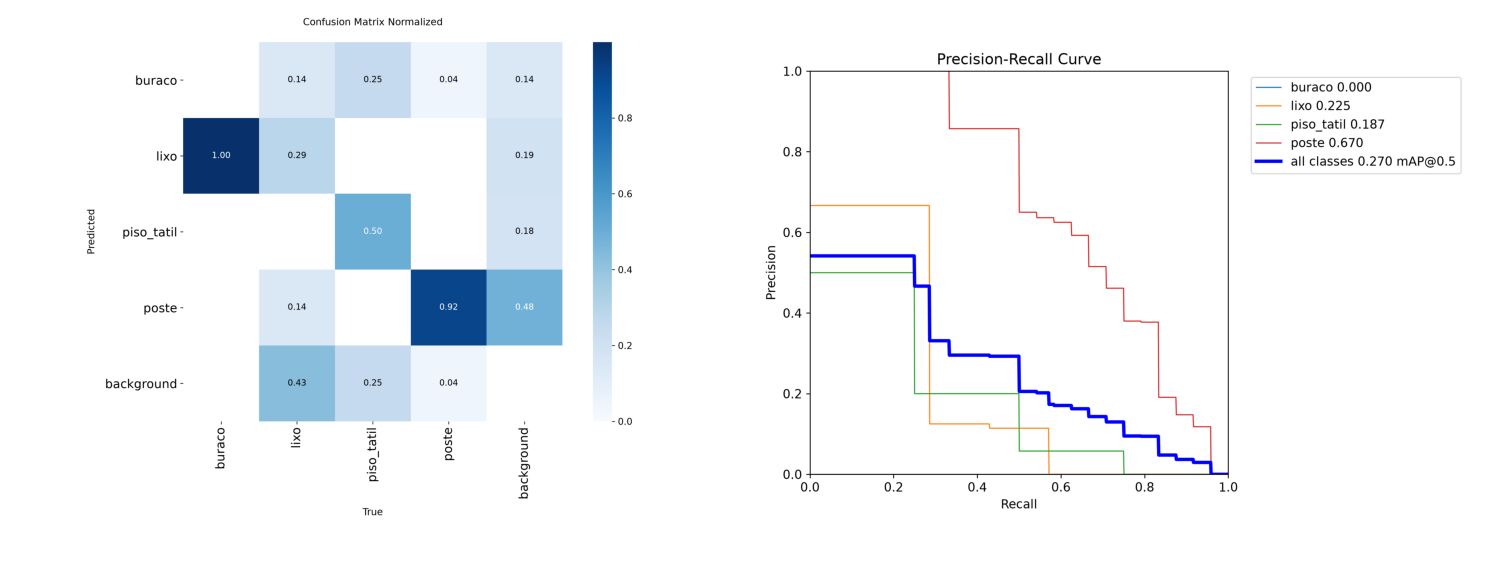

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(Image.open(RAIZ / 'runs/aval_test/confusion_matrix_normalized.png')); ax[0].axis('off')
pr = RAIZ / 'runs/aval_test/BoxPR_curve.png'
if not pr.exists(): pr = RAIZ / 'runs/aval_test/PR_curve.png'
ax[1].imshow(Image.open(pr)); ax[1].axis('off')
plt.tight_layout(); plt.show()

**Como ler:** a diagonal da matriz é a fração de objetos de cada classe detectados com a classe certa; a linha/coluna
`background` mostra objetos não detectados (falsos negativos) e detecções onde não havia objeto (falsos positivos).

## 6. Exemplos de predição no conjunto de teste

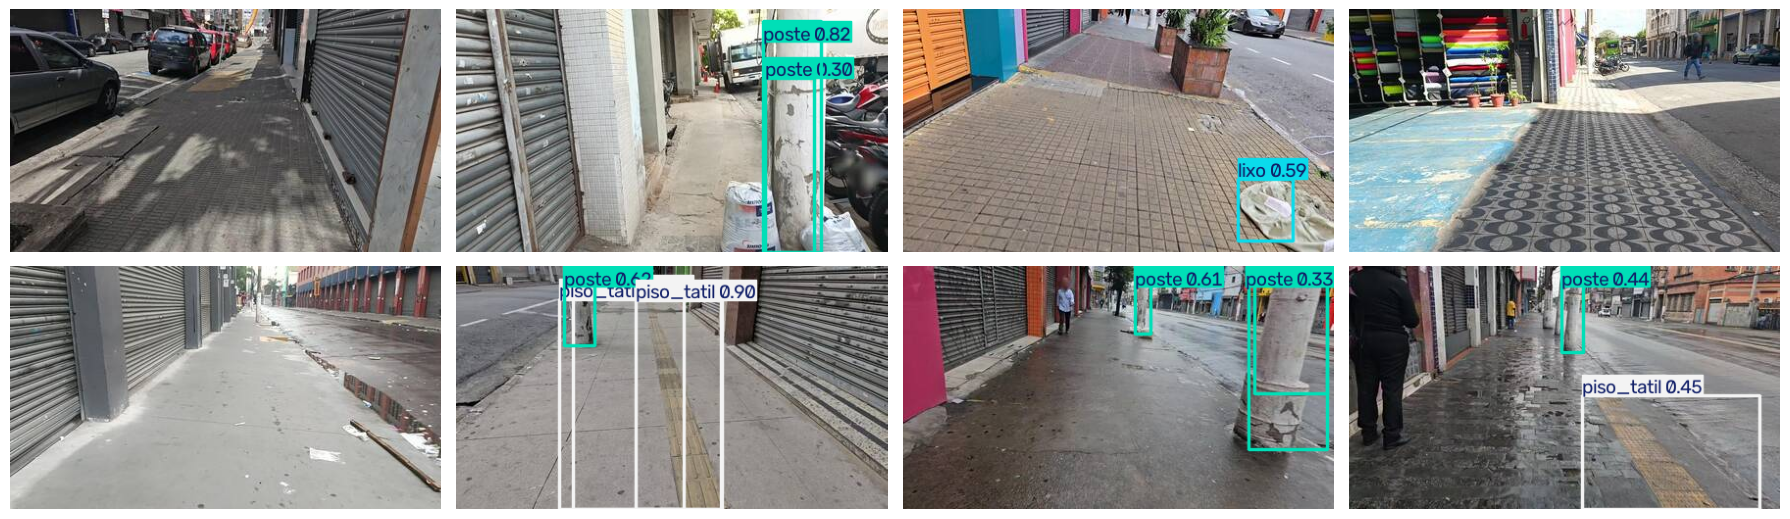

In [11]:
amostras = sorted((DATASET / 'test/images').glob('*.jpg'))[:8]
preds = best.predict([str(p) for p in amostras], imgsz=IMGSZ, conf=0.25, verbose=False)
fig, axs = plt.subplots(2, 4, figsize=(18, 5.5))
for a, p in zip(axs.flat, preds):
    a.imshow(p.plot()[..., ::-1]); a.axis('off')
plt.tight_layout(); plt.show()

## 7. Exportação para ONNX (inferência mobile)

O `yoloinferApp` roda o modelo no navegador do celular com **ONNX Runtime Web** (WASM/SIMD), então o formato de exportação é **ONNX**
(`opset 12`, entrada estática `[1,3,448,448]`, saída `[1, 4+4, N]` — o pós-processamento/NMS é feito em JavaScript pelo app).
Também gravamos um JSON com `imgsz` e os nomes das classes, que o app lê para desenhar os rótulos.

In [12]:
onnx_path = Path(best.export(format='onnx', imgsz=IMGSZ, opset=12, simplify=True, dynamic=False))
destino_app = RAIZ / 'app/public/models'
shutil.copy(onnx_path, destino_app / 'calcadas.onnx')
shutil.copy(onnx_path, RAIZ / 'model/calcadas.onnx')
shutil.copy(RUN / 'weights/best.pt', RAIZ / 'model/calcadas_best.pt')
import hashlib
meta = {'imgsz': IMGSZ, 'names': NOMES, 'modelo': 'YOLOv8n', 'treino': 'CPZÃO Auditoria de Calçadas',
        'versao': hashlib.md5(onnx_path.read_bytes()).hexdigest()[:8]}   # o app usa p/ invalidar cache
for d in (destino_app, RAIZ / 'model'):
    (d / 'calcadas.json').write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding='utf-8')
print(f'ONNX: {onnx_path.stat().st_size / 1e6:.1f} MB ->', destino_app / 'calcadas.onnx')

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CPU (AMD Ryzen 7 7800X3D 8-Core Processor)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 4.2 GFLOPs



PyTorch: starting from 'C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.pt' with input shape (1, 3, 448, 448) BCHW and output shape(s) (1, 8, 4116) (6.2 MB)



ONNX: starting export with onnx 1.23.2 opset 12...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success  1.2s, saved as 'C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.onnx' (12.1 MB)



Export complete (1.2s)
Results saved to C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.onnx
Predict:         yolo predict task=detect model=C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.onnx imgsz=448 
Validate:        yolo val task=detect model=C:\Users\rafae\AppData\Local\Temp\cp\repo\runs\calcadas\weights\best.onnx imgsz=448 data=C:\Users\rafae\AppData\Local\Temp\cp\repo\data\dataset\data.yaml  
Visualize:       https://netron.app


ONNX: 12.7 MB -> C:\Users\rafae\AppData\Local\Temp\cp\repo\app\public\models\calcadas.onnx


### Validação da exportação: ONNX Runtime vs PyTorch

Mesma entrada para os dois: cada imagem de teste é pré-processada **exatamente como o app faz** (letterbox quadrado
448×448 com padding preto, centralizado). Comparamos a saída bruta `[1, 8, 4116]` do ONNX Runtime com a do PyTorch
(`best.pt`) e também as detecções finais após limiar de confiança + NMS.

In [13]:
import onnxruntime as ort
import torch, torchvision
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
print('entrada:', sess.get_inputs()[0].name, sess.get_inputs()[0].shape, '| saída:', sess.get_outputs()[0].name, sess.get_outputs()[0].shape)
rede = best.model.float().eval().cpu()

def letterbox_app(path):  # mesmo pré-processamento de app/src/inference.js (modo letterbox)
    im = Image.open(path).convert('RGB'); W, H = im.size
    s = min(IMGSZ / W, IMGSZ / H); nw, nh = round(W * s), round(H * s)
    canvas = Image.new('RGB', (IMGSZ, IMGSZ)); canvas.paste(im.resize((nw, nh)), ((IMGSZ - nw) // 2, (IMGSZ - nh) // 2))
    return (np.asarray(canvas, dtype=np.float32) / 255).transpose(2, 0, 1)[None]

def deteccoes(y, conf=0.25):  # y: [8, N] -> NMS igual ao do app
    sc = y[4:].max(0); cl = y[4:].argmax(0); k = sc > conf
    if not k.any(): return set()
    cx, cy, w, h = y[:4, k]; bx = torch.tensor(np.stack([cx - w/2, cy - h/2, cx + w/2, cy + h/2], 1))
    keep = torchvision.ops.batched_nms(bx, torch.tensor(sc[k]), torch.tensor(cl[k]), 0.45).numpy()
    return {(int(cl[k][i]), *np.round(bx[i].numpy()).astype(int)) for i in keep}

dif_max, iguais, tot_pt = 0, 0, 0
for img in sorted((DATASET / 'test/images').glob('*.jpg')):
    x = letterbox_app(img)
    y_ox = sess.run(None, {sess.get_inputs()[0].name: x})[0][0]
    with torch.no_grad():
        y_pt = rede(torch.from_numpy(x))[0][0].numpy()
    dif_max = max(dif_max, float(np.abs(y_ox - y_pt).max()))
    d_ox, d_pt = deteccoes(y_ox), deteccoes(y_pt)
    tot_pt += len(d_pt); iguais += len(d_ox & d_pt)
print(f'diferença máxima na saída bruta: {dif_max:.4f} (coordenadas em pixels de 0 a 448; scores de 0 a 1)')
print(f'detecções idênticas (classe + caixa arredondada): {iguais}/{tot_pt}')

entrada: images [1, 3, 448, 448] | saída: output0 [1, 8, 4116]


diferença máxima na saída bruta: 0.0014 (coordenadas em pixels de 0 a 448; scores de 0 a 1)
detecções idênticas (classe + caixa arredondada): 28/28


## 8. Conclusões

Ver a seção **Resultados** do `README.md` para a discussão das métricas (gerada a partir de `model/metricas.json`).